# Soybean dataset review

Inspect the published YOLO boxes and the existing original-image grouped split before a first **hole-only** detector; no model is trained here. The downloaded README cites Shinde et al., Mendeley Data v2, DOI [10.17632/d97rjyk2tz.2](https://doi.org/10.17632/d97rjyk2tz.2), CC BY 4.0. The repository's [earlier audit](../research/soybean_bruchid/findings.md) describes how the grouping was derived from v1 filenames and image hashes. The dataset README uses the earlier title and calls `instance_metadata.csv` `annotation_metadata.csv`.

Run from the repository root or `notebooks/` after `uv sync --locked` (Python 3.14); launch Jupyter with `uv run jupyter lab` from the repository root and select the Python 3 kernel from the project environment. Data stays in `data/raw/Soybean_Seed_Dataset/`; no files are written. The `data.yaml` root points to the publisher's layout, so paths below use the actual local dataset root.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import yaml
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "CONTEXT.md").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data/raw/Soybean_Seed_Dataset"
MANIFEST = ROOT / "research/soybean_bruchid/resplit_by_original.csv"
assert (ROOT / "CONTEXT.md").exists() and DATA.is_dir(), "Run from the repository root or notebooks/ with the dataset extracted."
with (DATA / "data.yaml").open() as file:
    config = yaml.safe_load(file)
class_names = {int(key): value for key, value in config["names"].items()}
image_metadata = pd.read_csv(DATA / "image_metadata.csv")
instance_metadata = pd.read_csv(DATA / "instance_metadata.csv")
print("YAML:", config)
print("Image metadata columns:", image_metadata.columns.tolist())
print("Instance metadata columns:", instance_metadata.columns.tolist())
display(image_metadata.head(2), instance_metadata.head(2))


YAML: {'path': './soybean_dataset', 'train': 'train/images', 'val': 'validation/images', 'test': 'test/images', 'nc': 5, 'names': {0: 'Egg', 1: 'Hole', 2: 'Testa cracking', 3: 'Normal_Damage', 4: 'Healthy'}, 'metadata': {'total_images': 2726, 'total_instances': 14475, 'resolution': [640, 640]}}
Image metadata columns: ['Image Name', 'Split', 'Width', 'Height', 'File Path', 'Number of Objects', 'Classes Present']
Instance metadata columns: ['Instance ID', 'Image Name', 'Split', 'Class ID', 'Class Name', 'X_Center', 'Y_Center', 'Width', 'Height']


,Image Name,Split,Width,Height,File Path,Number of Objects,Classes Present
0,train_0001.jpg,train,640,640,soybean_dataset_clean\train\images\train_0001.jpg,7,"Egg, Hole"
1,train_0002.jpg,train,640,640,soybean_dataset_clean\train\images\train_0002.jpg,1,Healthy


,Instance ID,Image Name,Split,Class ID,Class Name,X_Center,Y_Center,Width,Height
0,INST_00001,train_0001.jpg,train,0,Egg,0.558594,0.517188,0.068750,0.035156
1,INST_00002,train_0001.jpg,train,1,Hole,0.265625,0.689063,0.129688,0.117188


## Published images and YOLO annotations

An image can contain several boxes and classes. **Image counts by class** count each image once per class; **annotation counts** count every box, so neither class-image counts nor their sum represents a mutually exclusive partition. Empty label files are included as images without boxes, not automatically verified negatives.


In [2]:
splits = ["train", "validation", "test"]
image_rows, box_rows, problems = [], [], []
for split in splits:
    image_dir, label_dir = DATA / split / "images", DATA / split / "labels"
    images = sorted(image_dir.glob("*.jpg"))
    labels = {path.stem: path for path in label_dir.glob("*.txt")}
    for image_path in images:
        label_path = labels.pop(image_path.stem, None)
        if label_path is None:
            problems.append(f"Missing label file: {split}/{image_path.name}")
        image_rows.append((split, image_path.name, image_path))
        if label_path is None:
            continue
        for line_number, line in enumerate(label_path.read_text().splitlines(), 1):
            try:
                values = line.split()
                if len(values) != 5:
                    raise ValueError("expected five fields")
                class_id = int(values[0])
                x, y, width, height = map(float, values[1:])
                if (class_id not in class_names or not (0 <= x <= 1 and 0 <= y <= 1)
                        or not (0 < width <= 1 and 0 < height <= 1)
                        or x - width / 2 < -1e-6 or x + width / 2 > 1 + 1e-6
                        or y - height / 2 < -1e-6 or y + height / 2 > 1 + 1e-6):
                    raise ValueError("unknown class or out-of-bounds box")
                box_rows.append((split, image_path.name, class_id, x, y, width, height))
            except ValueError as error:
                problems.append(f"{label_path}: line {line_number}: {error}")
    problems.extend(f"Label without image: {path}" for path in labels.values())
images = pd.DataFrame(image_rows, columns=["split", "image", "path"])
boxes = pd.DataFrame(box_rows, columns=["split", "image", "class_id", "x", "y", "width", "height"])
boxes["class"] = boxes["class_id"].map(class_names)
print("Structural / annotation problems:", len(problems))
print("\n".join(problems[:10]))
print("Published image counts:")
display(images.groupby("split").size().reindex(splits).rename("images").to_frame())
counts = boxes.groupby(["split", "class"]).size().rename("boxes")
per_image = boxes.drop_duplicates(["split", "image", "class"]).groupby(["split", "class"]).size().rename("images with class")
display(pd.concat([counts, per_image], axis=1).reset_index().sort_values(["split", "class"]))
print("Total images:", len(images), "total boxes:", len(boxes))
print("Images with no boxes:", len(images) - boxes[["split", "image"]].drop_duplicates().shape[0])


Structural / annotation problems: 0

Published image counts:


,images
split,
train,2180
validation,272
test,274


,split,class,boxes,images with class
0,test,Egg,1134,122
1,test,Healthy,115,115
2,test,Hole,249,102
3,test,Normal_Damage,24,19
4,test,Testa cracking,124,50
5,train,Egg,7536,785
6,train,Healthy,1148,1131
7,train,Hole,1417,633
8,train,Normal_Damage,193,171
9,train,Testa cracking,1051,412


Total images: 2726 total boxes: 14475
Images with no boxes: 43


In [3]:
# Compare per-image counts in the CSVs with the parsed label files.
keys = ["split", "image"]
actual_counts = boxes.groupby(keys).size().rename("label_boxes")
inventory = images.merge(actual_counts, on=keys, how="left").fillna({"label_boxes": 0})
image_csv = image_metadata.rename(columns={"Split": "split", "Image Name": "image", "Number of Objects": "metadata_boxes"})
instance_csv = instance_metadata.rename(columns={"Split": "split", "Image Name": "image", "Class ID": "class_id"})
print("Duplicate image keys (files / image CSV):", images.duplicated(keys).sum(), image_csv.duplicated(keys).sum())
comparison = inventory.merge(image_csv[keys + ["metadata_boxes"]], on=keys, how="outer", indicator=True)
print("Image CSV coverage:", comparison["_merge"].value_counts().to_dict())
print("Image CSV count mismatches:", (comparison["label_boxes"] != comparison["metadata_boxes"]).sum())
label_classes = boxes.groupby(keys + ["class_id"]).size().rename("labels")
metadata_classes = instance_csv.groupby(keys + ["class_id"]).size().rename("metadata")
class_comparison = pd.concat([label_classes, metadata_classes], axis=1).fillna(0)
print("Instance CSV count mismatches by image/class:", (class_comparison["labels"] != class_comparison["metadata"]).sum())
print("These count checks do not verify box coordinates or semantic correctness.")


Duplicate image keys (files / image CSV): 0 0
Image CSV coverage: {'both': 2726, 'left_only': 0, 'right_only': 0}
Image CSV count mismatches: 0
Instance CSV count mismatches by image/class: 0
These count checks do not verify box coordinates or semantic correctness.


## Examples

Deterministically select the first Hole image from each published split and one additional multi-class image. Boxes show the downloaded annotations, not a judgment that every visible object has been labelled.


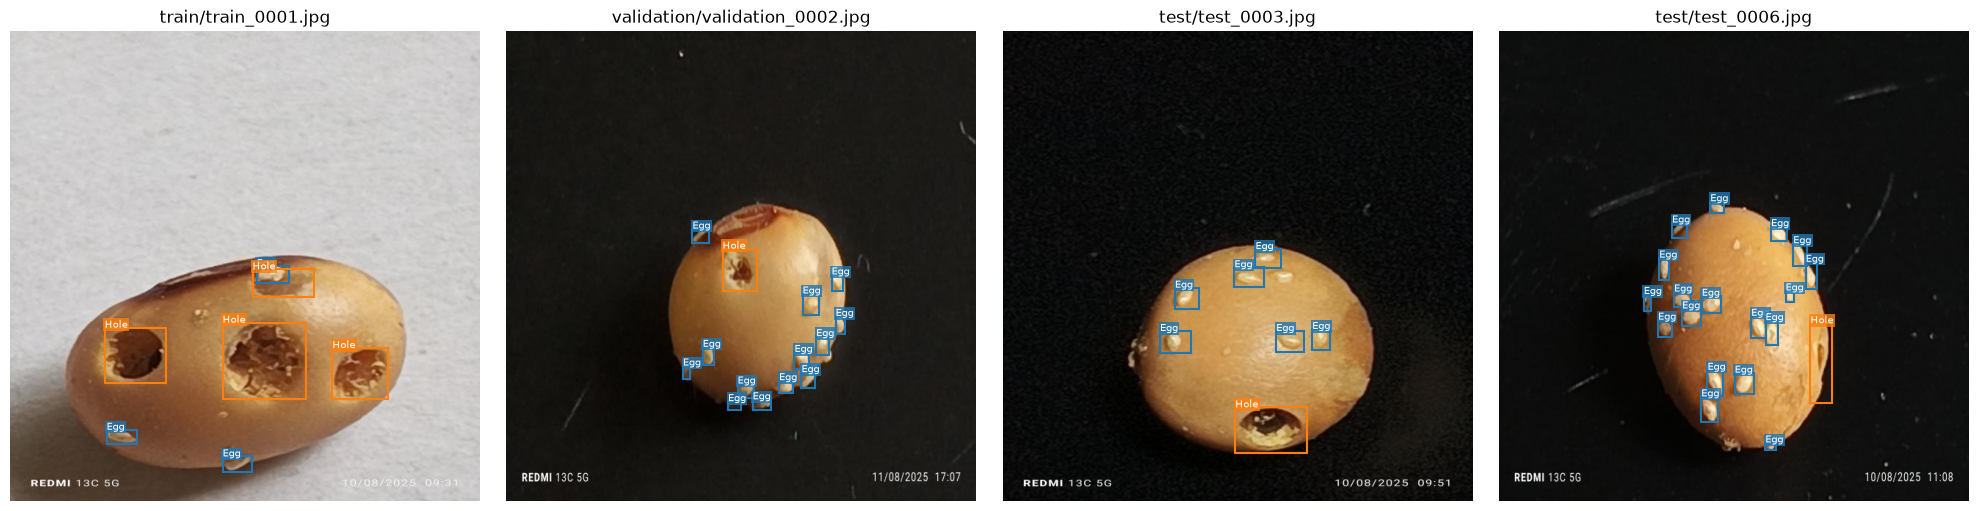

In [4]:
hole_id = next(key for key, value in class_names.items() if value.lower() == "hole")
selected = []
for split in splits:
    candidates = boxes[(boxes["split"] == split) & (boxes["class_id"] == hole_id)]
    if not candidates.empty:
        selected.append((split, sorted(candidates["image"])[0]))
class_diversity = boxes.groupby(keys)["class_id"].nunique()
for key in sorted(class_diversity[class_diversity > 1].index):
    if key not in selected:
        selected.append(key)
        break
fig, axes = plt.subplots(1, len(selected), figsize=(5 * len(selected), 5), squeeze=False)
colors = plt.get_cmap("tab10")
for axis, (split, image_name) in zip(axes[0], selected):
    image_path = DATA / split / "images" / image_name
    with Image.open(image_path) as image:
        axis.imshow(image.convert("RGB"))
        image_width, image_height = image.size
    for row in boxes[(boxes["split"] == split) & (boxes["image"] == image_name)].itertuples():
        left = (row.x - row.width / 2) * image_width
        top = (row.y - row.height / 2) * image_height
        color = colors(row.class_id)
        axis.add_patch(Rectangle((left, top), row.width * image_width, row.height * image_height,
                                 fill=False, edgecolor=color, linewidth=1.5))
        axis.text(left, top, class_names[row.class_id], color="white", fontsize=7,
                  bbox=dict(facecolor=color, alpha=0.8, pad=1, edgecolor="none"))
    axis.set_title(f"{split}/{image_name}")
    axis.axis("off")
plt.tight_layout()
plt.show()


## Existing grouped split

The folders above are the **published split**, not assumed leakage-free. The manifest is a prior artifact, not a newly recomputed split. Its `original_split` is checked against the v2 published folder; `new_split` uses `val` for validation. A name match does not verify file identity or the v1 hash-based grouping.


In [5]:
manifest = pd.read_csv(MANIFEST, keep_default_na=False)
print("Manifest columns:", manifest.columns.tolist())
print("Rows:", len(manifest), "duplicate image names:", manifest.duplicated("image_v2", keep=False).sum())
print("Duplicate downloaded image names:", images.duplicated("image", keep=False).sum())
ambiguous_manifest = manifest.loc[manifest.duplicated("image_v2", keep=False), "image_v2"]
ambiguous_files = images.loc[images.duplicated("image", keep=False), "image"]
print("Ambiguous manifest examples:", ambiguous_manifest.head(10).tolist())
print("Ambiguous downloaded filename examples:", ambiguous_files.head(10).tolist())
print("Discard reasons:", manifest["discard"].value_counts(dropna=False).to_dict())
display(manifest.groupby(["new_split", "discard"], dropna=False).size().rename("rows").to_frame())
# Outer join exposes missing matches; duplicate names flag ambiguous joins before interpreting counts.
matching = manifest.merge(inventory, left_on="image_v2", right_on="image", how="outer", indicator=True)
print("Manifest-to-files coverage:", matching["_merge"].value_counts().to_dict())
print("Published split mismatches:", ((matching["_merge"] == "both") & (matching["original_split"] != matching["split"])).sum())
print("Label count mismatches:", ((matching["_merge"] == "both") & (pd.to_numeric(matching["n_labels"], errors="coerce") != matching["label_boxes"])).sum())
print("Missing groups:", (manifest["group"] == "").sum())
print("Unmatched examples:")
display(matching.loc[matching["_merge"] != "both", ["image_v2", "image", "_merge"]].head(10))
kept = manifest[manifest["discard"] == ""].copy()
print("Kept rows with missing or unexpected new split:", (~kept["new_split"].isin(["train", "val", "test"])).sum())
print("Discarded rows with a new split:", ((manifest["discard"] != "") & (manifest["new_split"] != "")).sum())
display(kept.groupby("new_split").agg(images=("image_v2", "size"), groups=("group", "nunique")))
print("Groups assigned to multiple new splits:", (kept.groupby("group")["new_split"].nunique() > 1).sum())
# Published leakage measured only according to the existing manifest's group assignments.
group_splits = manifest.groupby("group")["original_split"].agg(set)
for split in ["validation", "test"]:
    overlap_groups = set(group_splits[group_splits.map(lambda values: "train" in values and split in values)].index)
    split_rows = manifest[manifest["original_split"] == split]
    print(f"Published {split} rows sharing a manifest group with train: {split_rows['group'].isin(overlap_groups).sum()} / {len(split_rows)}")


Manifest columns: ['image_v2', 'original_split', 'group', 'new_split', 'discard', 'n_labels', 'background', 'type']
Rows: 2726 duplicate image names: 0
Duplicate downloaded image names: 0
Ambiguous manifest examples: []
Ambiguous downloaded filename examples: []
Discard reasons: {'': 2434, 'exact copy (md5)': 249, 'extra v2 unlabeled': 32, 'unlabeled': 11}


rows
new_split discard                 
          exact copy (md5)     249
          extra v2 unlabeled    32
          unlabeled             11
test                           365
train                         1715
val                            354

Manifest-to-files coverage: {'both': 2726, 'left_only': 0, 'right_only': 0}
Published split mismatches: 0
Label count mismatches: 0
Missing groups: 0
Unmatched examples:


,image_v2,image,_merge


Kept rows with missing or unexpected new split: 0
Discarded rows with a new split: 0


,images,groups
new_split,,
test,365,175
train,1715,816
val,354,175


Groups assigned to multiple new splits: 0
Published validation rows sharing a manifest group with train: 217 / 272
Published test rows sharing a manifest group with train: 229 / 274


## Interpretation for a first hole-only detector

**Verified by the cells above:** counts, metadata count consistency, sample boxes and manifest coverage/group overlap are reported from the local files. Box-file validity and matching counts do **not** establish annotation completeness or biological correctness. Inspect the plotted examples; non-Hole boxes can coexist with Hole, and an image with no Hole box is not necessarily a reliable negative.

**Earlier audit reported, not independently re-audited here:** its 100-image manual review found 7 images with missing boxes, 5 with wrong classes and 3 with badly drawn boxes, plus 9 doubtful images; some Hole labels confused the hilum with a hole. It reported 32 of 33 new v2 images were unlabelled and many had visible defects, and Healthy boxes coexisted with defects in 353 images. The audit also found black backgrounds strongly associated with bruchid damage (505/513), and printed dates correlated with class. See [findings](../research/soybean_bruchid/findings.md) for methods, examples and limitations. These are risks of false negatives, ambiguous labels and shortcuts, not verified ground truth from the count checks.

Before training, manually review hole positives and candidate negatives, especially empty-label images and ambiguous hilum/window cases. Resolve manifest mismatches if any, use its retained original-photo groups only after validating the mapping, and keep one variant per test group for evaluation. Inspect or mask background/date cues and evaluate separately on light backgrounds and independent French pulse photos; the earlier audit's v1 hash matching and biological transfer have not been reproduced here. No model metrics or transfer performance are established by this review.
